# 01 · 数据探索 Data exploration

**Data Science Club · BIPH FindMy**

在相信任何指标之前，先看清楚我们拿什么数据来测试匹配引擎。
Before trusting any metric, look at the data the matching engine is tested on.

| 数据集 | 来源 | 用途 |
|---|---|---|
| **合成 Synthetic** | `matcher/eval/generate.py` 按模板生成，种子固定 | 拟合权重（种子 7）、测试（种子 2026，一个全新的"虚拟校园"） |
| **手写 Hand-written** | `matcher/data/handwritten_pairs.yaml`，模仿真实学生发帖 | 检查模型在"不像模板"的文字上是否依然有效 |
| **真实 Real** | 社团「描述物品」活动（[指南](../../docs/data-collection.md)） | 最诚实的数字，**还没采集** |

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "matcher").is_dir():  # works from the repo root or from matcher/notebooks
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

INDIGO, CYAN, MUTED, INK, ORANGE = "#3b3fb6", "#2bb5c4", "#9aa0b4", "#1d1f2e", "#c2410c"
plt.rcParams.update({
    "font.family": ["Noto Sans CJK SC", "DejaVu Sans"],  # Chinese labels need a CJK font
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
})
pd.set_option("display.max_colwidth", 70)

## 1. 合成的"虚拟校园" · The synthetic test campus

生成器故意把题目出得很难：

- **相似物品家族**：很多物品类别和颜色完全一样，也就是"六个黑色水杯"问题。
- **多语言**：45% 中文、40% 英文、15% 中英混写，其中一部分中文转成了繁体字。
- **会记错**：失主凭记忆描述，会记错颜色（navy 说成 blue）和地点。
- **生僻词**：约四分之一的描述用了词典里**没有**的说法（`heldout.yaml`），避免"用自己的词典考自己"。
- **噪音**：有错别字，有的捡到者会把关键细节藏进私密字段，有的物品根本没有对应的另一半。

In [2]:
from matcher.eval.run import synthetic_test, TEST_SEED

test_set, data = synthetic_test(900)  # exactly what the evaluation report uses
truth = test_set.truth
objects = data.objects
print(f"seed {TEST_SEED}: {len(objects)} objects in the whole world")
print(f"test split: {len(test_set.queries)} lost reports, {len(test_set.pool)} found reports, "
      f"{len(truth)} lost reports have their true match in the pool")

seed 2026: 900 objects in the whole world
test split: 114 lost reports, 163 found reports, 97 lost reports have their true match in the pool


In [3]:
rng = np.random.default_rng(1)
found_by_obj = {r.object_id: r for r in test_set.pool}
pairs = [(q, found_by_obj[q.object_id]) for q in test_set.queries if q.object_id in found_by_obj]
sample = [pairs[i] for i in rng.choice(len(pairs), 8, replace=False)]
pd.DataFrame([{"lost (owner, from memory)": q.text, "found (finder, looking at it)": f.text,
               "lang": f"{q.lang} → {f.lang}"} for q, f in sample])

,"lost (owner, from memory)","found (finder, looking at it)",lang
0,Missing: a navy blue jacket. Last seen at the canteen.,捡到深蓝色的耐克毛衣，刻着周可欣，在餐厅,en → zh
1,求助！丢了蓝pencil case，挂着动漫挂件，有印花，可能在front desk,"Foound a light blue pencil box with a anime keychain, with a flora...",mixed → en
2,丢失：灰涩的polo衫，最后一次见是在琴房,在班级捡到西装外套，已交到前台,zh → zh
3,丢失：白色polo衫，最后一次见是在实验室,A white polo shirt my initials E.T. are on the bottom found at the...,zh → en
4,"A jet black graphing device has a shark sticker, lost at the corri...",教室发现黑计算器，画着鲨鱼,en → zh
5,求助！丢了米白浴巾，有印花，可能在储物柜,Found a beige towel.,zh → en
6,我在寝室丢了彩色耐克短裤，午饭后有人看到吗？,Picked up a multicolored Nike pe kit has the name C.X. on it in th...,zh → en
7,在更衣室弄丢了多色泳衣，上面写着陈子豪,Picked up a multicolored swim cap has the name 陈子豪 on it near the ...,zh → en


## 2. 语言和长度 · Languages and length

25% of reports use at least one word the dictionary has never seen


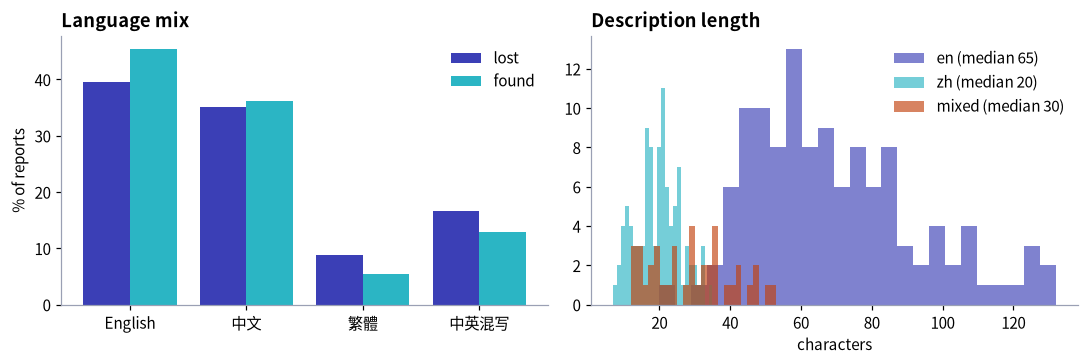

In [4]:
reports = test_set.queries + test_set.pool
langs = ["en", "zh", "zh-hant", "mixed"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for kind, color, dx in (("lost", INDIGO, -0.2), ("found", CYAN, 0.2)):
    rs = [r for r in reports if r.kind == kind]
    share = [100 * sum(r.lang == l for r in rs) / len(rs) for l in langs]
    axes[0].bar(np.arange(len(langs)) + dx, share, 0.4, color=color, label=kind)
axes[0].set_xticks(range(len(langs)), ["English", "中文", "繁體", "中英混写"])
axes[0].set_ylabel("% of reports")
axes[0].legend(frameon=False)
axes[0].set_title("Language mix", loc="left", fontweight="bold")

for lang, color in (("en", INDIGO), ("zh", CYAN), ("mixed", ORANGE)):
    lengths = [len(r.text) for r in reports if r.lang == lang]
    axes[1].hist(lengths, bins=25, alpha=0.65, color=color, label=f"{lang} (median {int(np.median(lengths))})")
axes[1].set_xlabel("characters")
axes[1].legend(frameon=False)
axes[1].set_title("Description length", loc="left", fontweight="bold")
fig.tight_layout()

held_out = 100 * np.mean([r.oov for r in reports])
print(f"{held_out:.0f}% of reports use at least one word the dictionary has never seen")

中文描述的字符数比英文少很多：一个汉字就相当于一个英文单词。这也是我们不按"词"切分中文、而是用**字符 n‑gram** 的原因之一，这样就不需要分词工具。

## 3. 类别和"撞款" · Categories and look-alikes

91% of objects have at least one look-alike with the same category and colour
largest look-alike groups: jacket/green ×63, id_card/white ×40, earbuds/white ×27, id_card/blue ×23, jacket/beige ×21


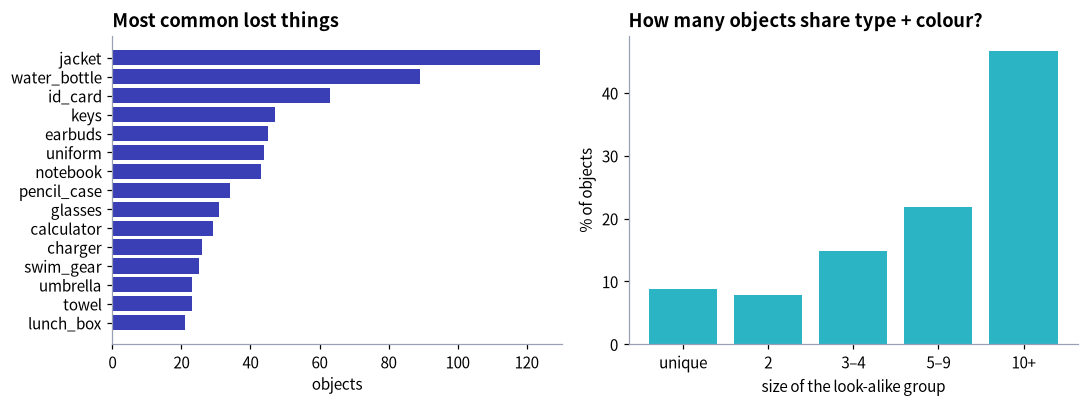

In [5]:
from collections import Counter

cats = Counter(o.category for o in objects.values())
top = cats.most_common(15)
families = Counter((o.category, o.colors[0]) for o in objects.values())
sizes = [families[(o.category, o.colors[0])] for o in objects.values()]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].barh([c for c, _ in top][::-1], [n for _, n in top][::-1], color=INDIGO)
axes[0].set_title("Most common lost things", loc="left", fontweight="bold")
axes[0].set_xlabel("objects")
bins = [1, 2, 3, 5, 10, 100]
labels = ["unique", "2", "3–4", "5–9", "10+"]
counts = [sum(lo <= s < hi for s in sizes) for lo, hi in zip(bins, bins[1:])]
axes[1].bar(labels, [100 * c / len(sizes) for c in counts], color=CYAN)
axes[1].set_title("How many objects share type + colour?", loc="left", fontweight="bold")
axes[1].set_ylabel("% of objects")
axes[1].set_xlabel("size of the look-alike group")
fig.tight_layout()

share = 100 * np.mean([s > 1 for s in sizes])
print(f"{share:.0f}% of objects have at least one look-alike with the same category and colour")
print("largest look-alike groups:", ", ".join(f"{c}/{col} ×{n}" for (c, col), n in families.most_common(5)))

大部分物品都有"撞款"，所以**只靠类别和颜色是不够的**。描述里的细节、特征标记（贴纸、刻字、凹痕）、地点和时间才是区分它们的关键。

## 4. NLP 抽取准不准 · How good is the extraction?

`matcher.extract` 用中英双语词典从描述里找出类别、颜色、品牌、地点和特征标记。网站会把这些结果显示成可以确认或修改的标签。
这里拿生成器知道的**真实答案**来检查抽取结果：

In [6]:
from matcher.extract import extract
from matcher.vocab import load_vocab

vocab = load_vocab()
rows = []
for r in reports:
    obj = objects[r.object_id]
    ex = extract(r.text, vocab)
    true_colors = set(obj.colors)
    got = set(ex.colors)
    rows.append({
        "kind": r.kind, "lang": r.lang, "held-out word": r.oov,
        "category found": ex.category is not None,
        "category correct": ex.category == obj.category,
        "colour precision": len(got & true_colors) / len(got) if got else np.nan,
        "colour recall": len(got & true_colors) / len(true_colors),
    })
ext = pd.DataFrame(rows)

def summary(df):
    return pd.Series({"reports": len(df),
                      "category found %": 100 * df["category found"].mean(),
                      "category correct %": 100 * df["category correct"].mean(),
                      "colour precision %": 100 * df["colour precision"].mean(),
                      "colour recall %": 100 * df["colour recall"].mean()}).round(1)

pd.DataFrame({"all": summary(ext),
              **{f"lang={l}": summary(ext[ext.lang == l]) for l in langs},
              "dictionary words": summary(ext[~ext["held-out word"]]),
              "held-out words": summary(ext[ext["held-out word"]]),
              "lost (from memory)": summary(ext[ext.kind == "lost"]),
              "found (looking at it)": summary(ext[ext.kind == "found"])}).T

,reports,category found %,category correct %,colour precision %,colour recall %
all,277.0,74.4,74.0,98.0,89.7
lang=en,119.0,66.4,66.4,96.4,91.2
lang=zh,99.0,83.8,82.8,98.9,88.9
lang=zh-hant,19.0,78.9,78.9,100.0,94.7
lang=mixed,40.0,72.5,72.5,100.0,85.0
dictionary words,209.0,98.1,98.1,98.4,90.9
held-out words,68.0,1.5,0.0,96.7,86.0
lost (from memory),114.0,73.7,73.7,97.0,85.5
found (looking at it),163.0,74.8,74.2,98.7,92.6


抽取失败的例子最有用，它们直接告诉我们词典该补哪些词。这也是 DS Club 可以持续改进的地方：往 `matcher/data/taxonomy.yaml` 里加同义词。

In [7]:
misses = [(r.text, objects[r.object_id].category, extract(r.text, vocab).category)
          for r in reports if extract(r.text, vocab).category != objects[r.object_id].category]
pd.DataFrame(misses[:12], columns=["description", "true category", "extracted"])

,description,true category,extracted
0,我在食堂丢了白的腕表，有挂绳，背面有点刮花，今天上午有人看到吗？,watch,None
1,"Has anyone seen a light blue campus pass with a heart dangling, wi...",id_card,None
2,"My black frames with scratches on the back, lost Please contact me!",glasses,None
3,求助！丢了绿色fob，吊着小熊，刻着王小明，可能在室内体育馆,keys,None
4,Missing: a fx-991 graphing device. Last seen.,calculator,None
5,"Has anyone seen a dark green pullover with stripes, has the name 王...",jacket,None
6,"A beige The North Face outer lyer has the name C.X. on it, with st...",jacket,None
7,求助！丢了粉红的象印杯字，侧面磕瘪了，可能在饭堂,water_bottle,None
8,Missing: my white campus pass. Last seen in the dorms.,id_card,None
9,"A purple sports canteen my initials L.Q. are on the bottom, lost n...",water_bottle,None


## 5. 手写数据 · The hand-written set

32 件物品 + 10 个干扰项，写法模仿真实学生发帖（表情、口语、繁体字、错别字）。注意：这些是 LLM 写的，**不是真实数据**。

In [8]:
from matcher.eval.datasets import load_handwritten

hw = load_handwritten()
hw_found = {r.object_id: r for r in hw.pool}
pd.DataFrame([{"lost": q.text, "found": hw_found[q.object_id].text} for q in hw.queries[:8]])

,lost,found
0,黑色保温杯 贴了恐龙贴纸，周二体育课后在体育馆不见了😭,Found a black thermos bottle with a green dinosaur sticker on the ...
1,"lost my black hydroflask, it has a big dent near the bottom from w...","black Hydro Flask, dented, left on a cafeteria table"
2,Black water bottle with K.L. written on the lid in silver marker,在化学实验室捡到一个黑色水杯
3,黑色Stanley大杯子（带把手那种），在操场跑道边上,"Stanley cup, black, with handle — found next to the track"
4,"plain black bottle nothing special, lost it at the library",图书馆二楼有个黑色的瓶子，没什么特征
5,黑色吸管杯，盖子是透明的，宿舍楼下不见了,"black kids-style bottle with a clear straw lid, dorm entrance"
6,AirPods Pro 白色 外面套着一个小猫的硅胶壳 在音乐室,found airpods pro case with a cat silicone cover in the music room
7,my airpods (not pro) have J.W. engraved on the case!! lost around ...,白色苹果耳机盒，走廊储物柜旁边捡到的


In [9]:
hw_rows = []
for r in hw.queries + hw.pool:
    ex = extract(r.text, vocab)
    hw_rows.append({"category found": ex.category is not None,
                    "category correct": r.category is not None and ex.category == r.category})
hw_ext = pd.DataFrame(hw_rows)
print(f"hand-written: {len(hw.queries)} lost, {len(hw.pool)} found")
print(f"category extracted for {100 * hw_ext['category found'].mean():.0f}% of reports, "
      f"matches the labelled category for {100 * hw_ext['category correct'].mean():.0f}%")

hand-written: 32 lost, 42 found
category extracted for 93% of reports, matches the labelled category for 92%


## 结论 · Takeaways

- **测试校园**：114 条丢失描述、163 条捡到描述。其中 97 条丢失描述在池子里有真正的另一半，其余模拟"东西还没被交上来"的情况。
- **撞款是常态**：91% 的物品至少有一件同类、同色的"撞款"，最大的一组是 63 件绿色外套。只看类别和颜色远远不够，描述里的细节、特征标记、地点和时间才是关键。
- **词典抽取的边界**：描述用的是词典里的词时，类别识别正确率 98%；遇到生僻说法（约四分之一的描述）几乎全部识别不出来。这正是需要多语言句向量来补的地方（见 notebook 02）。这也是 DS Club 可以持续改进的地方：把失败例子里的说法补进 `matcher/data/taxonomy.yaml`。
- **颜色**：抽出来的颜色 98% 是对的。失主凭记忆写的描述，颜色召回率（86%）比捡到者看着实物写的（93%）低，因为失主会忘记或记错。
- **英文更难**：英文描述的类别识别率（66%）低于中文（83%）。失败的大多是 "campus pass"、"fob"、"graphing device" 这类说法。
- **手写数据**上 93% 的描述能抽出类别，说明词典对"像真人写的"文字也基本有效。不过最终还是要用真实数据验证。